# 02 P2: the whole page read by Qwen3-VL 8B (the baseline)

**Question.** How well does Qwen3-VL 8B read the values when it sees each whole page at 150 dpi?

**Answer.** It finds about two thirds of the values: recall 0.672, precision 0.629 and F1 0.650 on the four drawings with full gold, and partial recall 0.543 on the other seven. It often writes a position or flatness frame as a plain diameter or length, so the value does not match. On the densest sheet, FTC-06, it finds only 56% of the values. It holds up on the sparser CTC-03 and on FTC-07 page 2. It read the 30 pages in 18 minutes, 36 seconds per page.

In [1]:
import sys
from pathlib import Path

sys.path.insert(0, str(Path.cwd()))  # notebooks run from experiments/drawing/
from notebook_helpers import (  # noqa: E402
    FULL_GOLD,
    case_table,
    evals,
    failures,
    page_image,
    stored_run,
)

## How the reader works

The reader is `WholePageReaderAdapter` in `src/resourcly/adapters/vlm_readers.py`, and the version is `versions/reader/whole-page-v1.toml`.

- Each page is rendered at 150 dpi (1650 x 1275 pixels, about 2,000 image tokens) and sent to Qwen3-VL 8B in one call with a 4,000-token limit.
- The prompt is Prompt B's glossary asked about the whole sheet. It returns one entry per callout, in the same shape as P1's crop answers, so the same code turns both into values. Only the way the model sees the callouts differs.
- An answer cut off by the token limit keeps its complete callouts. A callout repeated three or more times in a row (a repetition loop) is kept once.
- The title block and notes come from the PDF text layer, as in P1. Each answer item becomes one feature, typed by the same rule.

This is what the model sees on FTC-06 page 1:

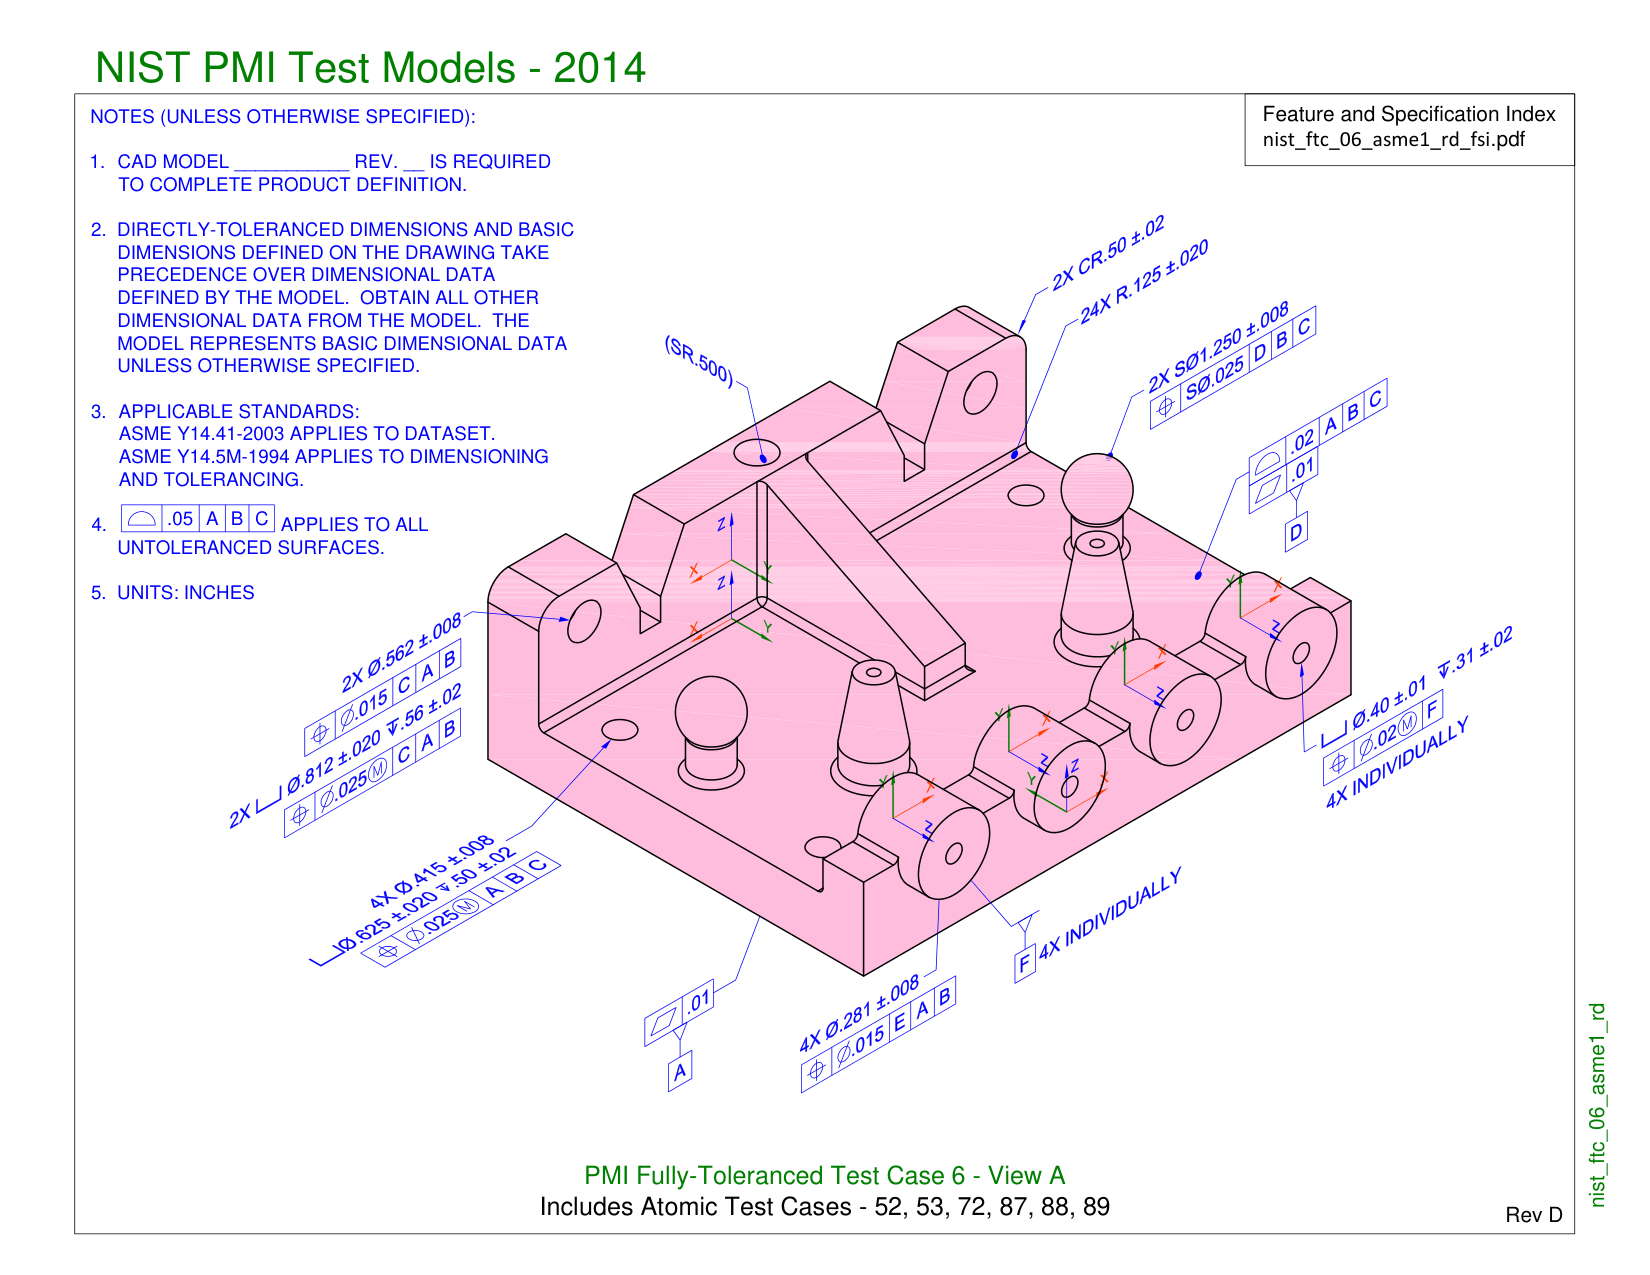

In [2]:
page_image("nist_ftc_06_asme1_rd", 1, dpi=150)

## The run

The run reads all 11 drawings and is made from the command line, as it takes 18 minutes:

```sh
uv run --extra vlm evals run reader --version whole-page-v1 --split all
```

This notebook reads it back from the run store. Four drawings have full gold (FTC-07 on page 2 only, through `page_coverage`) and give F1; the other seven have partial gold of about ten values and give recall only.

In [3]:
run_id = stored_run("whole-page-v1")

In [4]:
evals("show", run_id)

run reader-20261102T050825Z-2274  reader whole-page-v1 (hash 7c7fecc1c3fe)
split all, every case, case set 8231118bad61
started 2026-11-02T05:08:25Z  finished 2026-11-02T05:26:35Z  git 6bcab14 with local changes

metric          value
f1 (primary)    0.650
precision       0.629
recall          0.672
partial_recall  0.543
errors          0 of 11

case                  stratum  case_score  gold  predicted  matched  latency    error
nist_ctc_01_asme1_rd  full     0.800       23    22         18       40830 ms
nist_ctc_02_asme1_rc  partial  0.500       10    76         5        104985 ms
nist_ctc_03_asme1_rc  full     0.757       37    37         28       51198 ms
nist_ctc_04_asme1_rd  partial  0.600       10    35         6        32657 ms
nist_ctc_05_asme1_rd  partial  0.200       10    33         2        48836 ms
nist_ftc_06_asme1_rd  full     0.546       89    94         50       141572 ms
nist_ftc_07_asme1_rd  full     0.724       25    33         21       130154 ms
nist_ftc_08_asme1

'run reader-20261102T050825Z-2274  reader whole-page-v1 (hash 7c7fecc1c3fe)\nsplit all, every case, case set 8231118bad61\nstarted 2026-11-02T05:08:25Z  finished 2026-11-02T05:26:35Z  git 6bcab14 with local changes\n\nmetric          value\nf1 (primary)    0.650\nprecision       0.629\nrecall          0.672\npartial_recall  0.543\nerrors          0 of 11\n\ncase                  stratum  case_score  gold  predicted  matched  latency    error\nnist_ctc_01_asme1_rd  full     0.800       23    22         18       40830 ms\nnist_ctc_02_asme1_rc  partial  0.500       10    76         5        104985 ms\nnist_ctc_03_asme1_rc  full     0.757       37    37         28       51198 ms\nnist_ctc_04_asme1_rd  partial  0.600       10    35         6        32657 ms\nnist_ctc_05_asme1_rd  partial  0.200       10    33         2        48836 ms\nnist_ftc_06_asme1_rd  full     0.546       89    94         50       141572 ms\nnist_ftc_07_asme1_rd  full     0.724       25    33         21       130154 m

In [5]:
case_table(run_id)

,gold,gold values,predicted,matched,precision,recall,F1,pages,seconds,seconds per page,error
drawing,,,,,,,,,,,
nist_ctc_01_asme1_rd,full,23,22,18,0.818,0.783,0.800,1,40.8,40.8,None
nist_ctc_02_asme1_rc,partial,10,76,5,NaN,0.500,NaN,3,105.0,35.0,None
nist_ctc_03_asme1_rc,full,37,37,28,0.757,0.757,0.757,1,51.2,51.2,None
nist_ctc_04_asme1_rd,partial,10,35,6,NaN,0.600,NaN,1,32.7,32.7,None
nist_ctc_05_asme1_rd,partial,10,33,2,NaN,0.200,NaN,2,48.8,24.4,None
nist_ftc_06_asme1_rd,full,89,94,50,0.532,0.562,0.546,3,141.6,47.2,None
nist_ftc_07_asme1_rd,full,25,33,21,0.636,0.840,0.724,4,130.2,32.5,None
nist_ftc_08_asme1_rc,partial,10,105,5,NaN,0.500,NaN,4,166.6,41.7,None
nist_ftc_09_asme1_rd,partial,10,108,8,NaN,0.800,NaN,4,155.4,38.8,None


## Failure cases

The whole-page reader gives no box per callout, so extra predictions are listed without a crop.

**nist_ctc_01_asme1_rd**: 5 missed, 4 extra predictions

missed: page 1 `flatness` `▱ 0.2` value 0.2

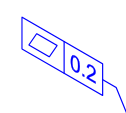

missed: page 1 `profile_of_a_surface` `⌓ 0.5 | A (all around)` value 0.5

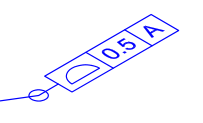

missed: page 1 `diameter` `⌀34.8 - 35.2` value [34.8, 35.2]

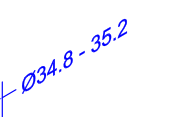

missed: page 1 `perpendicularity` `⊥ 1.5 | A` value 1.5

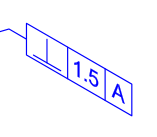

missed: page 1 `profile_of_a_surface` `⌓ 1.25 | A | B | C (A ↔ B)` value 1.25

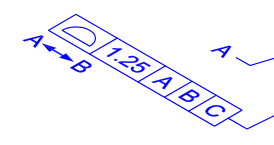

extra predictions: page 1 `linear` `0.2` value 0.2

extra predictions: page 1 `position` `⌖ 0.5 | A` value 0.5

extra predictions: page 1 `linear` `1.5 A` value 1.5

extra predictions: page 1 `position` `⌖ 1.25 | A | B | C` value 1.25

**nist_ctc_03_asme1_rc**: 9 missed, 9 extra predictions

missed: page 1 `profile_of_a_surface` `⌓ .03 | A | B | C` value 0.03

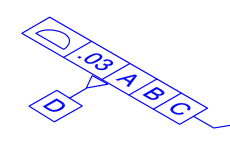

missed: page 1 `note` `SWITCH MOUNTING LOCATIONS` value None

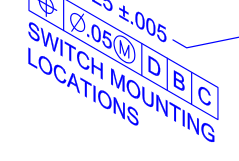

missed: page 1 `profile_of_a_surface` `⌓ .01` value 0.01

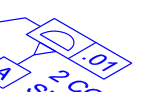

missed: page 1 `note` `2 COPLANAR SURFACES` value None

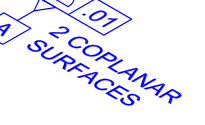

missed: page 1 `perpendicularity` `⊥ ⌀.01 | E` value 0.01

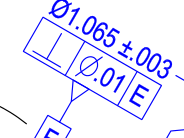

missed: page 1 `angularity` `∠ .04 | A` value 0.04

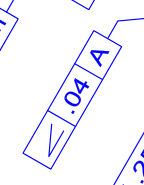

missed: page 1 `flatness` `▱ .005 / .25 X .25` value 0.005

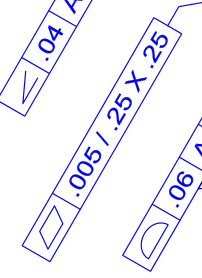

missed: page 1 `profile_of_a_surface` `⌓ .06 | A | B | C` value 0.06

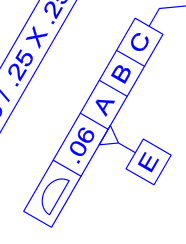

missed: page 1 `perpendicularity` `⊥ ⌀.01 | A` value 0.01

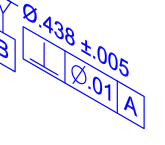

extra predictions: page 1 `diameter` `⌀.03` value 0.03

extra predictions: page 1 `note` `SWITCH MOUNTING` value None

extra predictions: page 1 `note` `LOCATIONS` value None

extra predictions: page 1 `position` `⌖ ⌀.01 | E` value 0.01

extra predictions: page 1 `position` `⌖ ⌀.04 | A` value 0.04

extra predictions: page 1 `position` `⌖ ⌀.005 | A | B | C` value 0.005

extra predictions: page 1 `diameter` `⌀.005 / 25 X .25` value 0.005

extra predictions: page 1 `position` `⌖ .06 | E` value 0.06

extra predictions: page 1 `position` `⌖ ⌀.01 | A` value 0.01

**nist_ftc_06_asme1_rd**: 39 missed, 44 extra predictions

missed: page 1 `profile_of_a_surface` `⌓ .05 | A | B | C` value 0.05

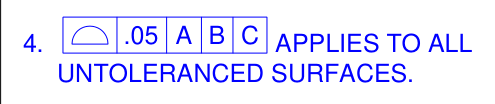

missed: page 1 `radius` `2X CR.50 ±.02` value 0.5

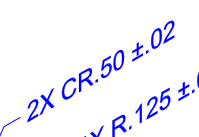

missed: page 1 `position` `⌖ S⌀.025 | D | B | C` value 0.025

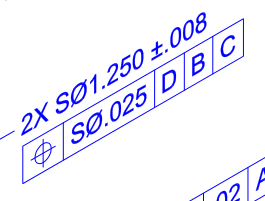

missed: page 1 `profile_of_a_surface` `⌓ .02 | A | B | C` value 0.02

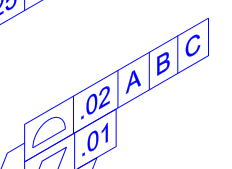

missed: page 1 `flatness` `▱ .01` value 0.01

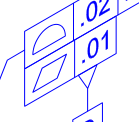

missed: page 1 `position` `⌖ ⌀.015 | C | A | B` value 0.015

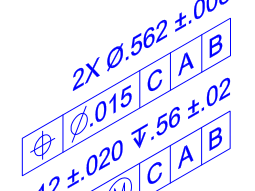

missed: page 1 `linear` `↧.56 ±.02` value 0.56

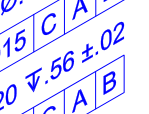

missed: page 1 `position` `⌖ ⌀.025Ⓜ | C | A | B` value 0.025

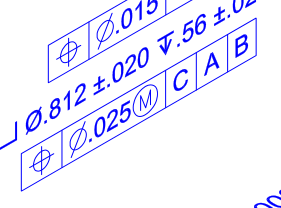

missed: page 1 `diameter` `⌴⌀.625 ±.020` value 0.625

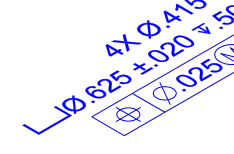

missed: page 1 `linear` `↧.50 ±.02` value 0.5

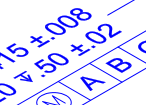

missed: page 1 `position` `⌖ ⌀.025Ⓜ | A | B | C` value 0.025

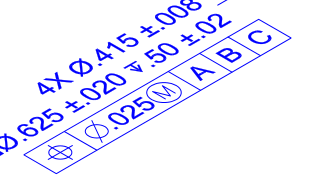

missed: page 1 `flatness` `▱ .01` value 0.01

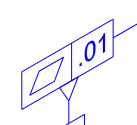

extra predictions: page 1 `diameter` `S⌀.025 D B C` value 0.025

extra predictions: page 1 `diameter` `⌀.02 A B C` value 0.02

extra predictions: page 1 `diameter` `⌀.01 D` value 0.01

extra predictions: page 1 `diameter` `⌀.015 C A B` value 0.015

extra predictions: page 1 `diameter` `⌀.56 ±.02` value 0.56

extra predictions: page 1 `diameter` `⌀.025(M) C A B` value 0.025

... (4 outputs left out)

extra predictions: page 1 `diameter` `⌀.02(M) F` value 0.02

extra predictions: page 1 `diameter` `⌀.015 E A B` value 0.015

**nist_ftc_07_asme1_rd**: 4 missed, 12 extra predictions

missed: page 2 `note` `4 COPLANAR SURFACES` value None

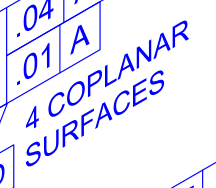

missed: page 2 `flatness` `▱ .01 / ⌀1.00` value 0.01

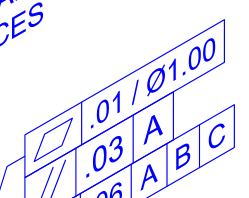

missed: page 2 `parallelism` `∥ .03 | A` value 0.03

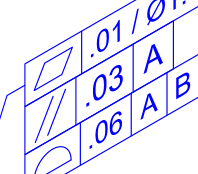

missed: page 2 `position` `⌖ ⌀.040Ⓜ | ⌀.045 MAX | A | B | C` value 0.04

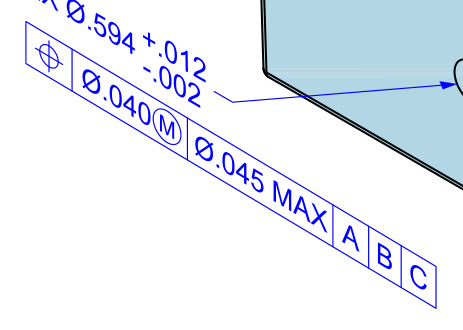

extra predictions: page 2 `note` `4 COPLANAR` value None

extra predictions: page 2 `note` `SURFACES` value None

extra predictions: page 2 `profile_of_a_surface` `⌓ .01 | A | B | C` value 0.01

extra predictions: page 2 `profile_of_a_surface` `⌓ .03 | A` value 0.03

extra predictions: page 2 `diameter` `.01 / ⌀1.00` value 0.01

extra predictions: page 2 `diameter` `⌀.040 M` value 0.04

... (2 outputs left out)

extra predictions: page 2 `datum_feature` `A` value None

extra predictions: page 2 `datum_feature` `B` value None

extra predictions: page 2 `datum_feature` `C` value None

extra predictions: page 2 `datum_feature` `E` value None

In [6]:
for case_id in FULL_GOLD:
    failures(run_id, case_id)